In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)

DATA_FILE = "yellow_tripdata_2026-08.parquet"
ZONE_FILE = "taxi_zone_lookup.csv"
SAMPLE_N = 500_000

LOADING THE DATASET

In [3]:
df = pd.read_parquet(DATA_FILE)
df.columns = df.columns.str.lower()

# KeepING only columns needed for this project
columns = [
    "vendorid", "tpep_pickup_datetime", "tpep_dropoff_datetime",
    "passenger_count", "trip_distance", "ratecodeid",
    "pulocationid", "dolocationid", "payment_type",
    "fare_amount", "tip_amount", "tolls_amount", "total_amount"
]
df = df[[c for c in columns if c in df.columns]]

# UsING a smaller random sample so the notebook runs faster
if SAMPLE_N and len(df) > SAMPLE_N:
    df = df.sample(SAMPLE_N, random_state=42)

df.head()

,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,pulocationid,dolocationid,payment_type,fare_amount,tip_amount,tolls_amount,total_amount
3017341,2,2026-08-20 21:23:56,2026-08-20 21:53:53,NaN,3.75,NaN,249,237,0,42.20,0.00,0.0,46.95
2749215,2,2026-08-11 18:13:41,2026-08-11 18:53:18,NaN,0.00,NaN,68,247,0,52.19,0.00,0.0,56.94
2452596,1,2026-08-01 22:25:19,2026-08-01 22:49:04,NaN,2.60,NaN,144,164,0,27.43,0.00,0.0,32.18
1278575,2,2026-08-16 19:19:10,2026-08-16 19:29:30,3.0,1.18,1.0,211,148,1,10.00,0.00,0.0,14.75
2144909,1,2026-08-28 13:17:26,2026-08-28 13:31:05,1.0,1.60,1.0,79,170,1,13.50,3.65,0.0,21.90


UNDERSTANDING THE DATA STRUCTURE

In [5]:
print("Rows and columns:", df.shape)
df.info()
display(df.describe().round(2))

Rows and columns: (500000, 13)
<class 'pandas.core.frame.DataFrame'>
Index: 500000 entries, 3017341 to 2076340
Data columns (total 13 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   vendorid               500000 non-null  int32         
 1   tpep_pickup_datetime   500000 non-null  datetime64[us]
 2   tpep_dropoff_datetime  500000 non-null  datetime64[us]
 3   passenger_count        362000 non-null  float64       
 4   trip_distance          500000 non-null  float64       
 5   ratecodeid             362000 non-null  float64       
 6   pulocationid           500000 non-null  int32         
 7   dolocationid           500000 non-null  int32         
 8   payment_type           500000 non-null  int64         
 9   fare_amount            500000 non-null  float64       
 10  tip_amount             500000 non-null  float64       
 11  tolls_amount           500000 non-null  float64       
 12  total_amoun

,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,pulocationid,dolocationid,payment_type,fare_amount,tip_amount,tolls_amount,total_amount
count,500000.00,500000,500000,362000.00,500000.00,362000.00,500000.00,500000.00,500000.00,500000.00,500000.00,500000.00,500000.00
mean,1.90,2026-08-16 05:21:01.300606,2026-08-16 05:38:13.024355,1.27,5.31,4.25,160.33,159.52,0.85,21.15,2.73,0.60,30.04
min,1.00,2009-01-01 14:39:49,2009-01-01 15:03:32,0.00,0.00,1.00,1.00,1.00,0.00,-310.30,-85.00,-46.54,-342.44
25%,2.00,2026-08-08 05:00:14,2026-08-08 05:19:09,1.00,1.07,1.00,114.00,107.00,0.00,10.00,0.00,0.00,17.34
50%,2.00,2026-08-15 21:29:34,2026-08-15 21:47:25,1.00,1.99,1.00,161.00,161.00,1.00,15.60,2.00,0.00,23.58
75%,2.00,2026-08-23 19:01:59,2026-08-23 19:20:44.750000,1.00,4.21,1.00,231.00,233.00,1.00,26.10,3.87,0.00,34.10
max,7.00,2026-08-31 23:59:51,2026-09-01 11:14:12,6.00,203505.71,99.00,265.00,265.00,4.00,950.00,140.00,90.00,965.92
std,0.71,NaN,NaN,0.67,502.06,17.24,66.49,70.72,0.66,18.98,3.95,2.32,22.87


In [ ]:
CHECKING MISSING VALUES AND DUPLICATES

In [7]:
print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values:
vendorid                      0
tpep_pickup_datetime          0
tpep_dropoff_datetime         0
passenger_count          138000
trip_distance                 0
ratecodeid               138000
pulocationid                  0
dolocationid                  0
payment_type                  0
fare_amount                   0
tip_amount                    0
tolls_amount                  0
total_amount                  0
dtype: int64
Duplicate rows: 0


CONVERTING DATES AND CREATE DURATION AND SPEED

In [9]:
df["tpep_pickup_datetime"] = pd.to_datetime(df["tpep_pickup_datetime"])
df["tpep_dropoff_datetime"] = pd.to_datetime(df["tpep_dropoff_datetime"])

df["duration_min"] = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

df["speed_mph"] = df["trip_distance"] / (df["duration_min"] / 60)
df["speed_mph"] = df["speed_mph"].replace([np.inf, -np.inf], np.nan)

display(df[["duration_min", "speed_mph"]].describe().round(2))

,duration_min,speed_mph
count,500000.00,493483.00
mean,17.20,16.66
std,25.81,1705.84
min,0.00,0.00
25%,8.47,6.95
50%,14.17,9.63
75%,22.10,13.74
max,6359.43,781618.37


REMOVING DUPLICATES AND INVALID RECORDS

In [11]:
df = df.drop_duplicates()

#  the most common pickup month in the data
main_month = df["tpep_pickup_datetime"].dt.to_period("M").mode()[0]


df = df[
    (df["tpep_pickup_datetime"].dt.to_period("M") == main_month) &
    (df["duration_min"].between(1, 180)) &
    (df["trip_distance"].between(0.1, 100)) &
    (df["fare_amount"].between(2.5, 500)) &
    (df["total_amount"] > 0) &
    (df["speed_mph"].between(1, 80))
].copy()

print("Rows after cleaning:", len(df))

Rows after cleaning: 469263


HANDLING MISSING PASSENGERS AND RATE CODES

In [13]:

df.loc[~df["passenger_count"].between(1, 6), "passenger_count"] = np.nan
df["passenger_count"] = df["passenger_count"].fillna(
    df["passenger_count"].mode()[0]
).astype(int)

# Use 99 to label missing/unknown rate codes
df["ratecodeid"] = df["ratecodeid"].fillna(99).astype(int)

print(df.isnull().sum())

vendorid                 0
tpep_pickup_datetime     0
tpep_dropoff_datetime    0
passenger_count          0
trip_distance            0
ratecodeid               0
pulocationid             0
dolocationid             0
payment_type             0
fare_amount              0
tip_amount               0
tolls_amount             0
total_amount             0
duration_min             0
speed_mph                0
dtype: int64


USEFUL COLUMNS

In [15]:
df["pickup_date"] = df["tpep_pickup_datetime"].dt.normalize()
df["pickup_hour"] = df["tpep_pickup_datetime"].dt.hour
df["pickup_dow"] = df["tpep_pickup_datetime"].dt.day_name()
df["is_weekend"] = df["pickup_dow"].isin(["Saturday", "Sunday"])

# Group hours into four time periods
df["time_bucket"] = pd.cut(
    df["pickup_hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Night (0-5)", "Morning (6-11)", "Afternoon (12-17)", "Evening (18-23)"]
)

#  payment codes into readable labels
payment_map = {
    1: "Credit card", 2: "Cash", 3: "No charge",
    4: "Dispute", 0: "Flex/Unknown"
}
df["payment_label"] = df["payment_type"].map(payment_map).fillna("Other")

# Tip percentage is analysed only for credit card trips
df["tip_pct"] = np.where(
    (df["payment_type"] == 1) & (df["fare_amount"] > 0),
    df["tip_amount"] / df["fare_amount"] * 100,
    np.nan
)
df.loc[df["tip_pct"] > 100, "tip_pct"] = np.nan

df["fare_per_mile"] = df["fare_amount"] / df["trip_distance"]
df.head()

,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,pulocationid,dolocationid,payment_type,fare_amount,...,duration_min,speed_mph,pickup_date,pickup_hour,pickup_dow,is_weekend,time_bucket,payment_label,tip_pct,fare_per_mile
3017341,2,2026-08-20 21:23:56,2026-08-20 21:53:53,1,3.75,99,249,237,0,42.20,...,29.950000,7.512521,2026-08-20,21,Thursday,False,Evening (18-23),Flex/Unknown,NaN,11.253333
2452596,1,2026-08-01 22:25:19,2026-08-01 22:49:04,1,2.60,99,144,164,0,27.43,...,23.750000,6.568421,2026-08-01,22,Saturday,True,Evening (18-23),Flex/Unknown,NaN,10.550000
1278575,2,2026-08-16 19:19:10,2026-08-16 19:29:30,3,1.18,1,211,148,1,10.00,...,10.333333,6.851613,2026-08-16,19,Sunday,True,Evening (18-23),Credit card,0.000000,8.474576
2144909,1,2026-08-28 13:17:26,2026-08-28 13:31:05,1,1.60,1,79,170,1,13.50,...,13.650000,7.032967,2026-08-28,13,Friday,False,Afternoon (12-17),Credit card,27.037037,8.437500
2072505,1,2026-08-27 14:46:05,2026-08-27 15:58:52,1,19.70,1,132,65,1,87.00,...,72.783333,16.239982,2026-08-27,14,Thursday,False,Afternoon (12-17),Credit card,20.804598,4.416244


ADDING ZONE NAMES

In [21]:
if os.path.exists(ZONE_FILE):
    zones = pd.read_csv(ZONE_FILE)
    zone_names = zones.set_index("LocationID")["Zone"]
    borough_names = zones.set_index("LocationID")["Borough"]

    df["pu_zone"] = df["pulocationid"].map(zone_names)
    df["do_zone"] = df["dolocationid"].map(zone_names)
    df["pu_borough"] = df["pulocationid"].map(borough_names)

    df["is_airport_trip"] = (
        df["pu_zone"].str.contains("Airport", na=False) |
        df["do_zone"].str.contains("Airport", na=False)
    )
else:
    print("Zone lookup file not found; skip geography analysis.")

SUMMARY STATISTICS AND OUTLIERS

In [23]:
columns = ["trip_distance", "duration_min", "fare_amount", "total_amount"]
display(df[columns].describe().round(2))

# IQR upper fences: values above these may be outliers
for col in columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    upper_fence = q3 + 1.5 * iqr
    print(col, "upper fence:", round(upper_fence, 2))

,trip_distance,duration_min,fare_amount,total_amount
count,469263.00,469263.00,469263.00,469263.00
mean,3.74,17.24,21.00,30.03
std,4.37,12.14,17.35,21.37
min,0.10,1.00,2.97,4.50
25%,1.18,8.80,10.00,17.43
50%,2.10,14.33,15.60,23.51
75%,4.42,22.18,25.48,33.94
max,96.17,171.98,500.00,603.60


trip_distance upper fence: 9.28
duration_min upper fence: 42.26
fare_amount upper fence: 48.7
total_amount upper fence: 58.7


In [ ]:
HISTOGRAM

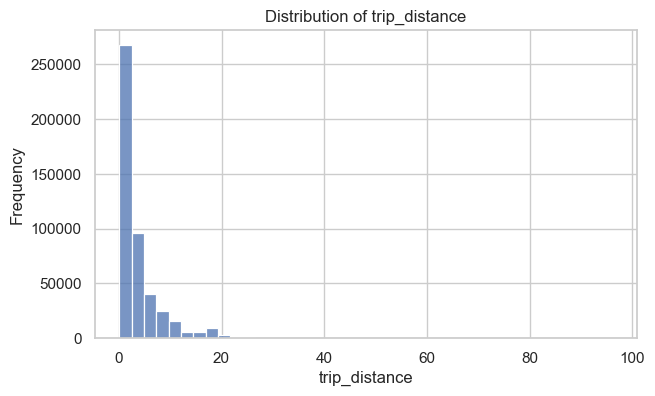

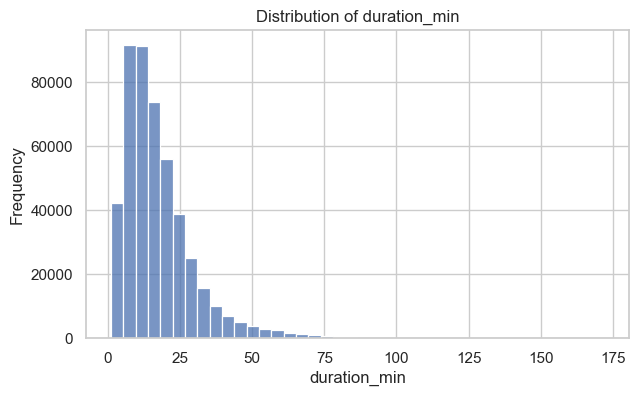

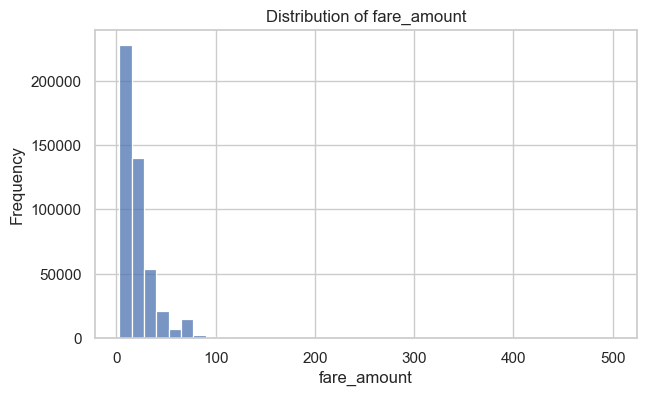

In [25]:
for col in ["trip_distance", "duration_min", "fare_amount"]:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col], bins=40)
    plt.title("Distribution of " + col)
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

BOX PLOTS

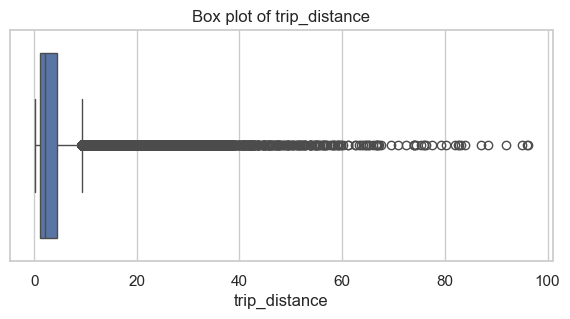

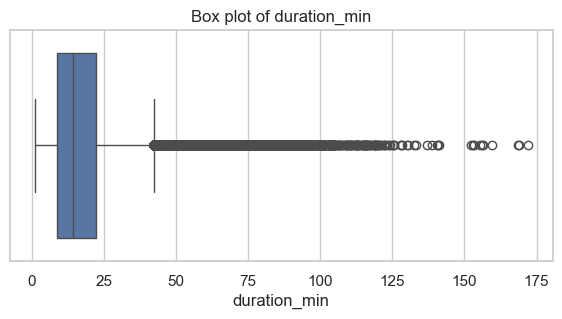

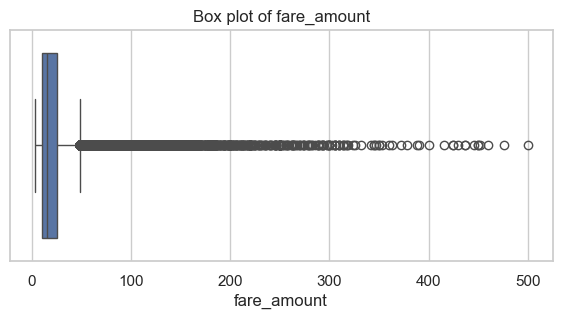

In [27]:
for col in ["trip_distance", "duration_min", "fare_amount"]:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[col])
    plt.title("Box plot of " + col)
    plt.show()

In [ ]:
PASSENGER COUNTS, PAYMENT TYPES, RATES CODES

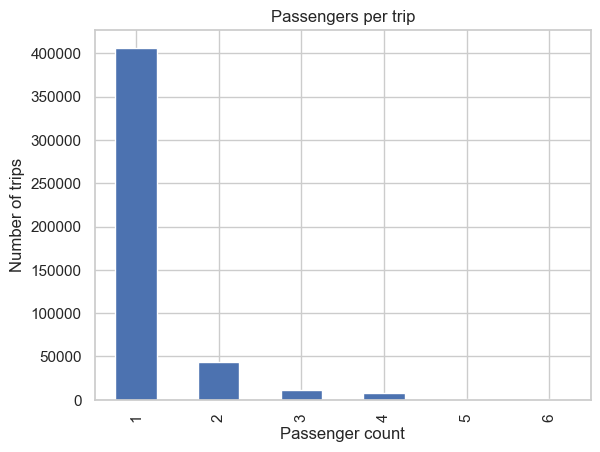

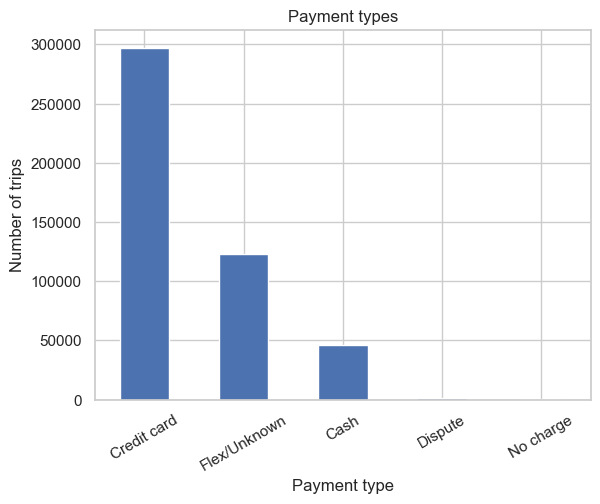

Payment percentages:
payment_label
Credit card     63.4
Flex/Unknown    26.2
Cash             9.9
Dispute          0.3
No charge        0.2
Name: proportion, dtype: float64


In [29]:
df["passenger_count"].value_counts().sort_index().plot(kind="bar")
plt.title("Passengers per trip")
plt.xlabel("Passenger count")
plt.ylabel("Number of trips")
plt.show()

df["payment_label"].value_counts().plot(kind="bar")
plt.title("Payment types")
plt.xlabel("Payment type")
plt.ylabel("Number of trips")
plt.xticks(rotation=30)
plt.show()

print("Payment percentages:")
print((df["payment_label"].value_counts(normalize=True) * 100).round(1))

In [ ]:
TRIPS BY HOUR: WEEKDAY VS WEEKEND

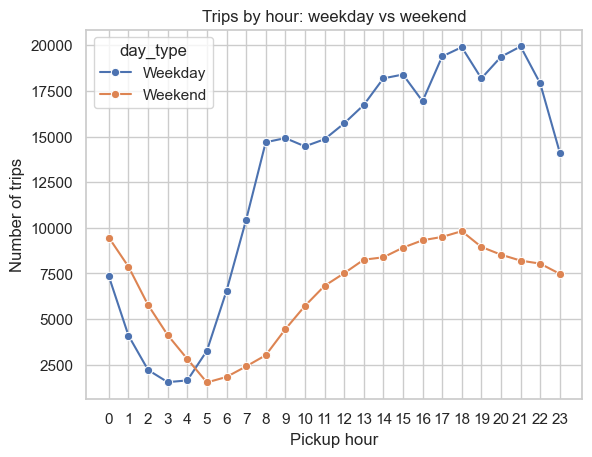

   day_type  pickup_hour  trips
21  Weekday           21  19936
42  Weekend           18   9813


In [31]:
hourly = df.groupby(["is_weekend", "pickup_hour"]).size().reset_index(name="trips")
hourly["day_type"] = hourly["is_weekend"].map({True: "Weekend", False: "Weekday"})

sns.lineplot(data=hourly, x="pickup_hour", y="trips", hue="day_type", marker="o")
plt.title("Trips by hour: weekday vs weekend")
plt.xlabel("Pickup hour")
plt.ylabel("Number of trips")
plt.xticks(range(24))
plt.show()

print(hourly.loc[hourly.groupby("day_type")["trips"].idxmax(), ["day_type", "pickup_hour", "trips"]])

BUSIEST WEEKDAY AND HOUR HEATMAP

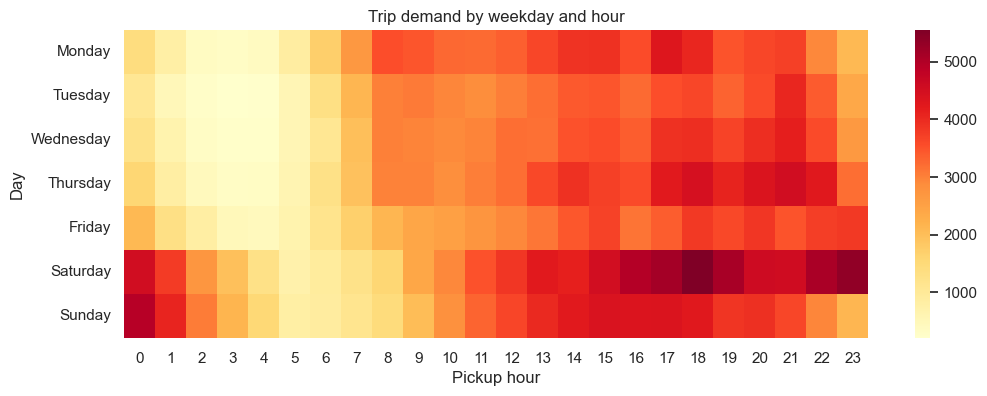

Busiest day/hour: ('Saturday', 18)


In [33]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

heat = pd.crosstab(df["pickup_dow"], df["pickup_hour"])
heat = heat.reindex(day_order)

plt.figure(figsize=(12, 4))
sns.heatmap(heat, cmap="YlOrRd")
plt.title("Trip demand by weekday and hour")
plt.xlabel("Pickup hour")
plt.ylabel("Day")
plt.show()

print("Busiest day/hour:", heat.stack().idxmax())

DAILY TRIP COUNTS

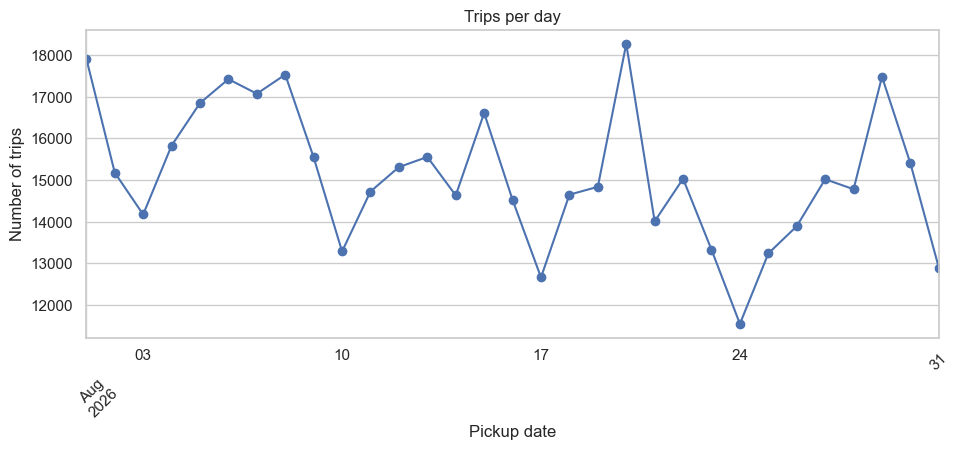

Three busiest days:
pickup_date
2026-08-20    18272
2026-08-01    17919
2026-08-08    17534
dtype: int64


In [35]:
daily = df.groupby("pickup_date").size()

daily.plot(figsize=(11, 4), marker="o")
plt.title("Trips per day")
plt.xlabel("Pickup date")
plt.ylabel("Number of trips")
plt.xticks(rotation=45)
plt.show()

print("Three busiest days:")
print(daily.nlargest(3))

SPEED BY HOUR (TRAFFIC PROXY)

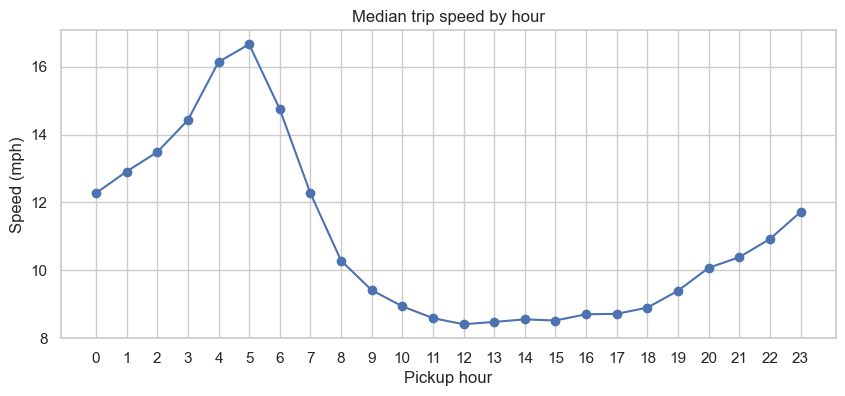

Slowest hour: 12
Fastest hour: 5


In [37]:
speed_by_hour = df.groupby("pickup_hour")["speed_mph"].median()

speed_by_hour.plot(figsize=(10, 4), marker="o")
plt.title("Median trip speed by hour")
plt.xlabel("Pickup hour")
plt.ylabel("Speed (mph)")
plt.xticks(range(24))
plt.show()

print("Slowest hour:", speed_by_hour.idxmin())
print("Fastest hour:", speed_by_hour.idxmax())

REVENUE BY HOUR

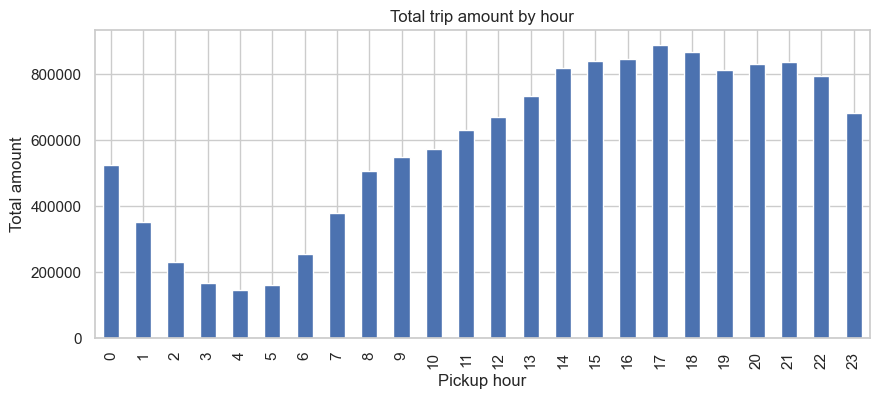

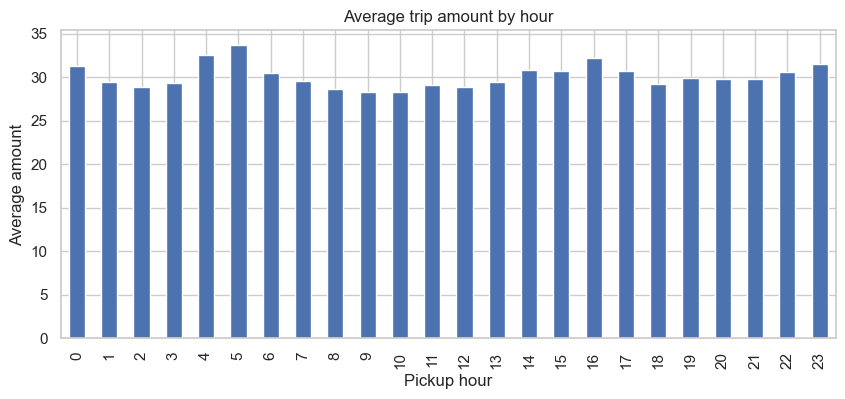

Highest total amount hour: 17
Highest average amount hour: 5


In [39]:
revenue = df.groupby("pickup_hour")["total_amount"].agg(["sum", "mean"])

revenue["sum"].plot(kind="bar", figsize=(10, 4))
plt.title("Total trip amount by hour")
plt.xlabel("Pickup hour")
plt.ylabel("Total amount")
plt.show()

revenue["mean"].plot(kind="bar", figsize=(10, 4))
plt.title("Average trip amount by hour")
plt.xlabel("Pickup hour")
plt.ylabel("Average amount")
plt.show()

print("Highest total amount hour:", revenue["sum"].idxmax())
print("Highest average amount hour:", revenue["mean"].idxmax())

DISTANCE VS FARE AND CORRELATION

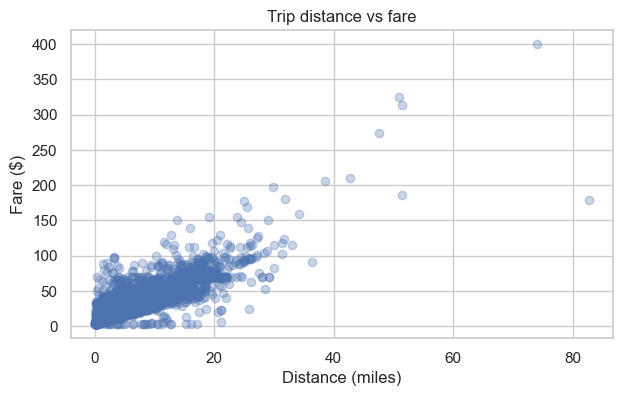

,trip_distance,duration_min,fare_amount,tip_amount,total_amount,speed_mph
trip_distance,1.00,0.81,0.91,0.43,0.90,0.72
duration_min,0.81,1.00,0.84,0.40,0.83,0.30
fare_amount,0.91,0.84,1.00,0.45,0.97,0.56
tip_amount,0.43,0.40,0.45,1.00,0.60,0.23
total_amount,0.90,0.83,0.97,0.60,1.00,0.56
speed_mph,0.72,0.30,0.56,0.23,0.56,1.00


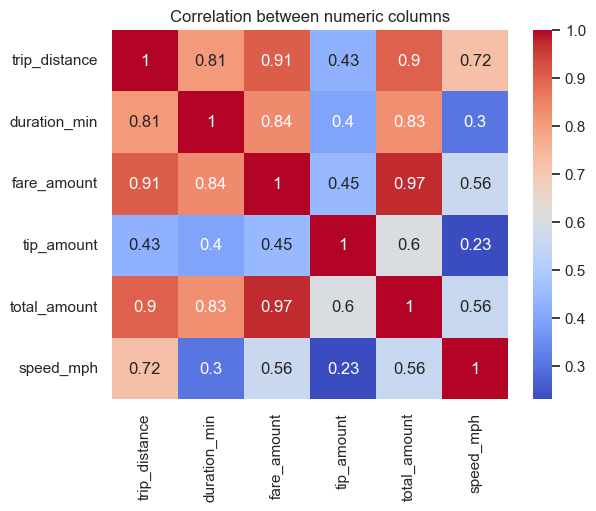

In [41]:
sample = df.sample(min(20000, len(df)), random_state=42)

plt.figure(figsize=(7, 4))
plt.scatter(sample["trip_distance"], sample["fare_amount"], alpha=0.3)
plt.title("Trip distance vs fare")
plt.xlabel("Distance (miles)")
plt.ylabel("Fare ($)")
plt.show()

corr_cols = [
    "trip_distance", "duration_min", "fare_amount",
    "tip_amount", "total_amount", "speed_mph"
]
display(df[corr_cols].corr().round(2))

sns.heatmap(df[corr_cols].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation between numeric columns")
plt.show()

FARE PER MILE BY DISTANCE GROUP

,trips,median_fare_per_mile
distance_band,,
0-1,91965,10.70
1-2,133834,7.96
2-3,72691,6.79
3-5,67994,5.77
5-10,64493,4.54
10-20,34139,4.03
20+,4147,3.51


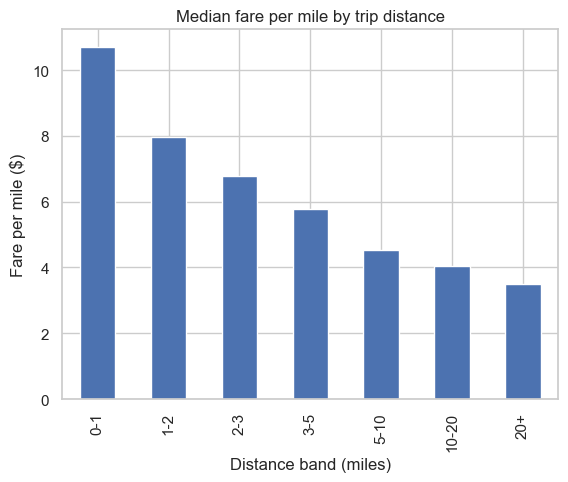

In [43]:
df["distance_band"] = pd.cut(
    df["trip_distance"],
    bins=[0, 1, 2, 3, 5, 10, 20, 100],
    labels=["0-1", "1-2", "2-3", "3-5", "5-10", "10-20", "20+"]
)

fare_by_distance = df.groupby("distance_band", observed=False).agg(
    trips=("fare_amount", "count"),
    median_fare_per_mile=("fare_per_mile", "median")
)
display(fare_by_distance.round(2))

fare_by_distance["median_fare_per_mile"].plot(kind="bar")
plt.title("Median fare per mile by trip distance")
plt.xlabel("Distance band (miles)")
plt.ylabel("Fare per mile ($)")
plt.show()

PAYMENT MIX BY TIME OF DAY

payment_label,Cash,Credit card,Dispute,Flex/Unknown,No charge
time_bucket,,,,,
Night (0-5),7.3,45.3,0.4,46.9,0.1
Morning (6-11),10.4,61.5,0.3,27.7,0.2
Afternoon (12-17),11.9,69.9,0.3,17.7,0.2
Evening (18-23),8.5,63.9,0.3,27.1,0.2


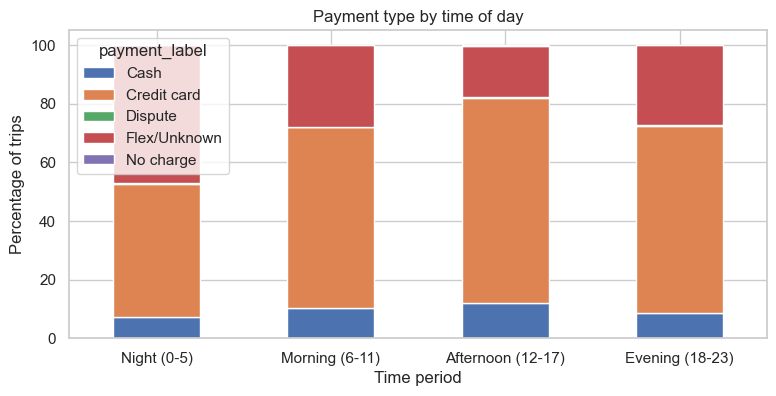

In [45]:
payment_time = pd.crosstab(
    df["time_bucket"], df["payment_label"], normalize="index"
) * 100

display(payment_time.round(1))
payment_time.plot(kind="bar", stacked=True, figsize=(9, 4))
plt.title("Payment type by time of day")
plt.ylabel("Percentage of trips")
plt.xlabel("Time period")
plt.xticks(rotation=0)
plt.show()

TIP PERCENTAGE FOR CARD TRIPS

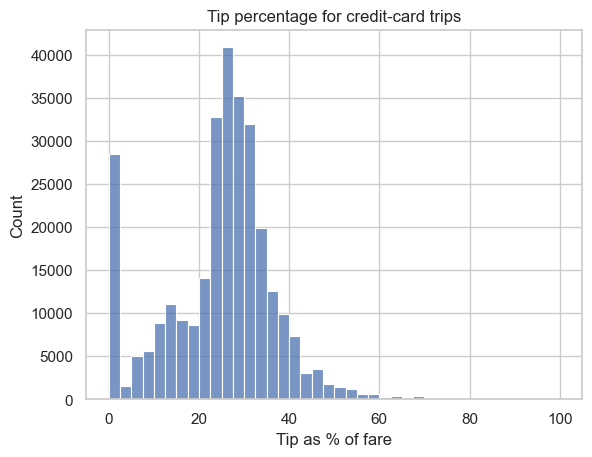

Median tip percentage: 26.42
Trips with no tip (%): 9.21


In [47]:
card = df[df["tip_pct"].notna()]

sns.histplot(card["tip_pct"], bins=40)
plt.title("Tip percentage for credit-card trips")
plt.xlabel("Tip as % of fare")
plt.show()

print("Median tip percentage:", round(card["tip_pct"].median(), 2))
print("Trips with no tip (%):", round((card["tip_pct"] == 0).mean() * 100, 2))

TIP PERCENTAGE BY HOUR

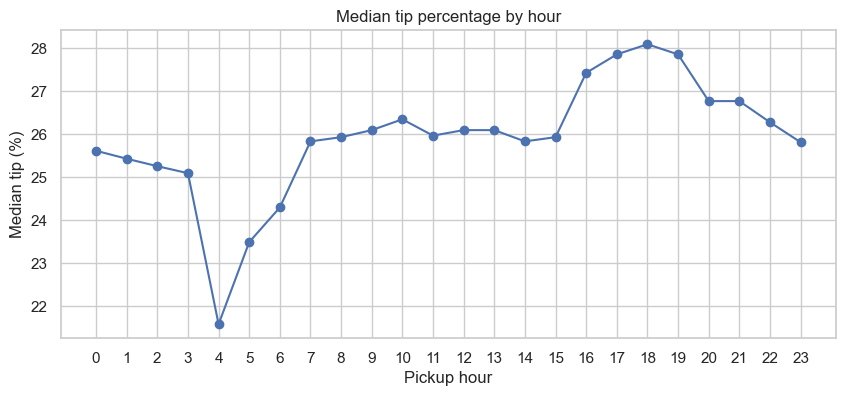

In [49]:
tip_by_hour = card.groupby("pickup_hour")["tip_pct"].median()

tip_by_hour.plot(figsize=(10, 4), marker="o")
plt.title("Median tip percentage by hour")
plt.xlabel("Pickup hour")
plt.ylabel("Median tip (%)")
plt.xticks(range(24))
plt.show()

In [ ]:
TOP PICKUP ZONES AND POPULAR ROUTES

In [51]:
if "pu_zone" in df.columns:
    print("Top pickup zones:")
    print(df["pu_zone"].value_counts().head(10))

    print("Top pickup boroughs:")
    print(df["pu_borough"].value_counts())

    routes = df.groupby(["pu_zone", "do_zone"]).size().sort_values(ascending=False).head(10)
    print("Top routes:")
    print(routes)

Top pickup zones:
pu_zone
JFK Airport                     21826
Midtown Center                  19637
Upper East Side South           18307
Penn Station/Madison Sq West    16747
Upper East Side North           14866
Midtown East                    14246
Times Sq/Theatre District       13781
East Village                    13594
East Chelsea                    13035
Murray Hill                     12945
Name: count, dtype: int64
Top pickup boroughs:
pu_borough
Manhattan        408527
Queens            44132
Brooklyn          14097
Bronx              2006
Unknown             382
Staten Island        38
EWR                   4
Name: count, dtype: int64
Top routes:
pu_zone                do_zone              
Upper East Side South  Upper East Side North    2210
Upper East Side North  Upper East Side South    1781
Upper East Side South  Upper East Side South    1598
Upper East Side North  Upper East Side North    1259
Upper East Side South  Midtown Center           1240
Midtown Center      

COMPARE AIRPORT AND NON AIRPORT TRIPS

In [53]:
if "is_airport_trip" in df.columns:
    airport_summary = df.groupby("is_airport_trip").agg(
        trips=("fare_amount", "count"),
        median_distance=("trip_distance", "median"),
        median_fare=("fare_amount", "median"),
        median_total=("total_amount", "median"),
        median_tip_pct=("tip_pct", "median")
    )
    display(airport_summary.round(2))

,trips,median_distance,median_fare,median_total,median_tip_pct
is_airport_trip,,,,,
False,426083,1.9,14.28,22.26,27.02
True,43180,11.4,51.30,75.20,23.29


Hypothesis test 1 night tips vs other tips (Welch t-test)

In [55]:
night_tips = card.loc[card["time_bucket"] == "Night (0-5)", "tip_pct"]
other_tips = card.loc[card["time_bucket"] != "Night (0-5)", "tip_pct"]

t_stat, p_value = stats.ttest_ind(night_tips, other_tips, equal_var=False)

print("Night mean tip %:", round(night_tips.mean(), 2))
print("Other mean tip %:", round(other_tips.mean(), 2))
print("p-value:", p_value)

if p_value < 0.05:
    print("Reject H0: the mean tip percentages are significantly different.")
else:
    print("Fail to reject H0: no significant difference was found.")

Night mean tip %: 21.7
Other mean tip %: 24.92
p-value: 7.329113697679093e-239
Reject H0: the mean tip percentages are significantly different.


Hypothesis test 2 weekend vs weekday trip distances

In [57]:
weekend_distance = df.loc[df["is_weekend"], "trip_distance"]
weekday_distance = df.loc[~df["is_weekend"], "trip_distance"]

u_stat, p_value = stats.mannwhitneyu(
    weekend_distance, weekday_distance, alternative="two-sided"
)

print("Weekend median distance:", weekend_distance.median())
print("Weekday median distance:", weekday_distance.median())
print("p-value:", p_value)

if p_value < 0.05:
    print("Reject H0: the trip-distance distributions differ.")
else:
    print("Fail to reject H0: no significant difference was found.")

Weekend median distance: 2.42
Weekday median distance: 1.97
p-value: 0.0
Reject H0: the trip-distance distributions differ.


Hypothesis test 3  payment type and time of day (chi-square)

In [59]:
subset = df[df["payment_label"].isin(["Credit card", "Cash"])]
table = pd.crosstab(subset["time_bucket"], subset["payment_label"])

chi2, p_value, dof, expected = stats.chi2_contingency(table)

display(table)
print("Chi-square:", chi2)
print("p-value:", p_value)

if p_value < 0.05:
    print("Reject H0: payment type is associated with time of day.")
else:
    print("Fail to reject H0: no significant association was found.")

payment_label,Cash,Credit card
time_bucket,,
Night (0-5),3752,23361
Morning (6-11),10436,61517
Afternoon (12-17),18656,109911
Evening (18-23),13591,102538


Chi-square: 497.9703124356959
p-value: 1.3138079443525327e-107
Reject H0: payment type is associated with time of day.


PROJECT INSIGHTS

In [61]:
print("Rows analysed:", len(df))
print("Median trip distance:", round(df["trip_distance"].median(), 2), "miles")
print("Median duration:", round(df["duration_min"].median(), 2), "minutes")
print("Median fare: $", round(df["fare_amount"].median(), 2))
print("Most common payment type:", df["payment_label"].mode()[0])
print("Busiest pickup hour:", df["pickup_hour"].mode()[0])
print("Trips under 2 miles (%):", round((df["trip_distance"] < 2).mean() * 100, 2))
print("Median card tip (%):", round(card["tip_pct"].median(), 2))

Rows analysed: 469263
Median trip distance: 2.1 miles
Median duration: 14.33 minutes
Median fare: $ 15.6
Most common payment type: Credit card
Busiest pickup hour: 18
Trips under 2 miles (%): 47.53
Median card tip (%): 26.42
